# A small conversational language model

Fine-tunes [`distilgpt2`](https://huggingface.co/distilbert/distilgpt2) (82M parameters) on [DailyDialog](https://aclanthology.org/I17-1099/), a set of 13,118 everyday English conversations, so that it continues a dialogue turn by turn.

The notebook measures the model before and after fine-tuning with the same validation dialogues and the same prompts. All the code lives in `src/conversational_lm.py`; the notebook calls it.

In [1]:
import os, sys, warnings
from pathlib import Path

warnings.filterwarnings("ignore")
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
import datasets, transformers
datasets.disable_progress_bars()
transformers.logging.set_verbosity_error()

import matplotlib.pyplot as plt
import numpy as np
import torch

sys.path.insert(0, str(Path("src").resolve()))
import conversational_lm as lm

args = lm.build_parser().parse_args(["train"])
print(f"torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}")
print(f"device: {'cuda' if torch.cuda.is_available() else 'cpu'}")
print(f"train dialogues: {args.train_samples}, epochs: {args.epochs}, batch size: {args.batch_size}")

torch 2.15.0+cpu, transformers 5.22.2, datasets 5.1.0
device: cpu
train dialogues: 2000, epochs: 1.0, batch size: 8


## 1. Data

In [2]:
train_raw, eval_raw = lm.load_splits(args.train_samples, args.eval_samples)
example = train_raw[0]["dialog"]
print("Raw turns:")
for turn in example[:4]:
    print("  ", repr(turn))

Raw turns:
   "finally we're on board ! "
   " yes . It was so crowded . I'm worn-out . Let's find our seats . "
   ' are they window seats or aisle seats ? '
   ' let me see ... yes , one window seat and one aisle seat . '


DailyDialog stores each conversation as a list of turns, tokenised with spaces around punctuation. `format_dialog` cleans the spacing, writes one turn per line with alternating speakers `A:` and `B:`, and closes the conversation with the end-of-text token. That token is what lets the model learn where a conversation ends.

In [3]:
tokenizer, base_model = lm.load_model(args.model_name)
print(lm.format_dialog(example, tokenizer.eos_token))

A: finally we're on board!
B: yes. It was so crowded. I'm worn-out. Let's find our seats.
A: are they window seats or aisle seats?
B: let me see... yes, one window seat and one aisle seat.
A: ok. But can I trade my seat with you? I prefer the one near the window. I'm a terrible flyer. I always get airsick and can never relax until after I've landed.
B: that's fine. I'd like to be on the aisle anyway. It's easier to get in and out.
A: thanks. Where shall we put our luggage?
B: I think the smaller carry-on bag can go in the overhead compartment, and the others can go under the seat.
A: good idea.
B: don't forget to keep the seat belt on.
A: ok. Hope it's a pleasant trip.
B: yes!
A: and no hijackers.
B: oh, you have too wild of an imagination.<|endoftext|>


2000 training dialogues, 500 validation dialogues
tokens per dialogue: median 118, 95th percentile 256, truncated at 256: 9.8%


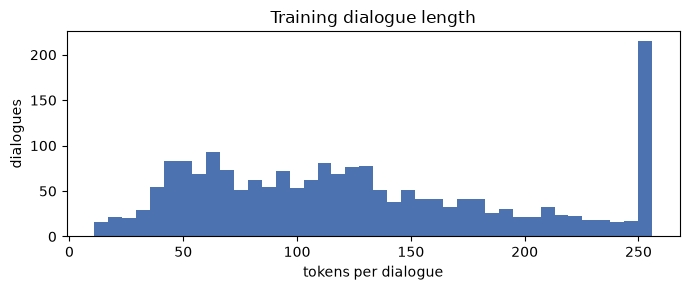

In [4]:
train_ds = lm.tokenize_split(train_raw, tokenizer, args.max_length)
eval_ds = lm.tokenize_split(eval_raw, tokenizer, args.max_length)
lengths = np.array([len(x) for x in train_ds["input_ids"]])
print(f"{len(train_ds)} training dialogues, {len(eval_ds)} validation dialogues")
print(f"tokens per dialogue: median {np.median(lengths):.0f}, 95th percentile {np.percentile(lengths, 95):.0f}, "
      f"truncated at {args.max_length}: {(lengths >= args.max_length).mean():.1%}")

plt.figure(figsize=(7, 3))
plt.hist(lengths, bins=40, color="#4c72b0")
plt.xlabel("tokens per dialogue")
plt.ylabel("dialogues")
plt.title("Training dialogue length")
plt.tight_layout()

## 2. The base model

Perplexity on the validation dialogues measures how surprised the model is by real conversations (lower is better). The replies use greedy decoding, so they are reproducible and comparable before and after training.

In [5]:
PROMPTS = [
    ["Hello, how are you today?"],
    ["Can you tell me how to get to the train station?"],
    ["I'm thinking about changing jobs."],
    ["What would you like for dinner tonight?"],
]

def show_replies(model):
    model.eval()
    for history in PROMPTS:
        print(f"A: {history[-1]}")
        print(f"B: {lm.reply(model, tokenizer, history, sample=False)}")
        print()

base_trainer = lm.build_trainer(base_model, tokenizer, train_ds, eval_ds, args)
base_ppl = lm.perplexity(base_trainer)
print(f"Validation perplexity of {args.model_name}: {base_ppl:.1f}\n")
show_replies(base_model)

{'eval_loss': '3.025', 'eval_model_preparation_time': '0.0008', 'eval_runtime': '80.75', 'eval_samples_per_second': '6.192', 'eval_steps_per_second': '0.78', 'epoch': 0}
Validation perplexity of distilgpt2: 20.6

A: Hello, how are you today?


B: I'm a little bit of an old man. My dad was in the middle of my life when he got married and we were having dinner at our house on Sunday night (I had to go back

A: Can you tell me how to get to the train station?


B: I can't. It's a very long journey, but it takes about two hours and half of my time on board! The trains are all over town so there is no need for any extra travel

A: I'm thinking about changing jobs.


B: What do you think of the new job market?

A: What would you like for dinner tonight?


B: I'd love to have a good meal. But it's not going to be easy, because we're all in the same boat and there are so many different things that can happen at any time!



## 3. Fine-tuning

GPT-2 has no padding token, so the end-of-text token is reused for padding. The stock `DataCollatorForLanguageModeling` hides every padding-token id from the loss, which would also hide the real end of each conversation. `CausalLMCollator` masks by attention mask instead, so only the padding is ignored.

{'loss': '2.883', 'grad_norm': '5.17', 'learning_rate': '4.9e-05', 'epoch': '0.2'}


{'loss': '2.737', 'grad_norm': '5.22', 'learning_rate': '3.775e-05', 'epoch': '0.4'}


{'loss': '2.723', 'grad_norm': '4.315', 'learning_rate': '2.525e-05', 'epoch': '0.6'}


{'loss': '2.705', 'grad_norm': '4.521', 'learning_rate': '1.275e-05', 'epoch': '0.8'}


{'loss': '2.676', 'grad_norm': '4.615', 'learning_rate': '2.5e-07', 'epoch': '1'}
{'train_runtime': '1171', 'train_samples_per_second': '1.708', 'train_steps_per_second': '0.214', 'train_loss': '2.745', 'epoch': '1'}
training time: 19.5 min, final training loss: 2.745


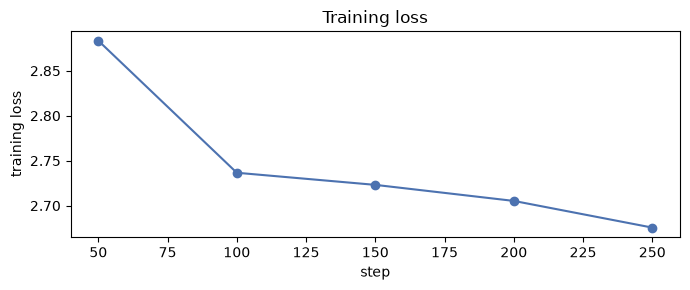

In [6]:
torch.manual_seed(lm.SEED)
_, model = lm.load_model(args.model_name)
trainer = lm.build_trainer(model, tokenizer, train_ds, eval_ds, args)
result = trainer.train()
print(f"training time: {result.metrics['train_runtime'] / 60:.1f} min, final training loss: {result.metrics['train_loss']:.3f}")

history = [h for h in trainer.state.log_history if "loss" in h]
plt.figure(figsize=(7, 3))
plt.plot([h["step"] for h in history], [h["loss"] for h in history], marker="o", color="#4c72b0")
plt.xlabel("step")
plt.ylabel("training loss")
plt.title("Training loss")
plt.tight_layout()

## 4. After fine-tuning

In [7]:
tuned_ppl = lm.perplexity(trainer)
print(f"Validation perplexity: {base_ppl:.1f} before, {tuned_ppl:.1f} after ({1 - tuned_ppl / base_ppl:.0%} lower)\n")
show_replies(model)

{'eval_loss': '2.622', 'eval_runtime': '129.1', 'eval_samples_per_second': '3.874', 'eval_steps_per_second': '0.488', 'epoch': '1'}
Validation perplexity: 20.6 before, 13.8 after (33% lower)

A: Hello, how are you today?


B: I'm a student at the University of California. My parents have been studying English since my high school years ago and they're very interested in learning to read literature or study music for their children. They

A: Can you tell me how to get to the train station?


B: I'm going there. It's a very busy day, but it is also quite crowded and noisy! How about this one for lunch or dinner on Friday afternoon when we go back home from work tomorrow

A: I'm thinking about changing jobs.


B: What's the problem? Is it a job loss or an accident, and how do you know that your company is in trouble for hiring people who are not qualified to work full time as employees of our

A: What would you like for dinner tonight?


B: I'd love to have a good meal.



In [8]:
# A longer exchange: the model plays B and sees the whole conversation so far.
conversation = ["Hi, I'd like to book a table for two.", ]
conversation.append(lm.reply(model, tokenizer, conversation, sample=False))
conversation.append("Tomorrow at eight, if possible.")
conversation.append(lm.reply(model, tokenizer, conversation, sample=False))
conversation.append("Great. Do you have a table by the window?")
conversation.append(lm.reply(model, tokenizer, conversation, sample=False))
for i, turn in enumerate(conversation):
    print(f"{'AB'[i % 2]}: {turn}")

A: Hi, I'd like to book a table for two.
B: Yes, please! How about you? What's the price of your room here? Do you have any other ideas on how much it will cost if we can afford that space in our living rooms or
A: Tomorrow at eight, if possible.
B: That sounds great and good too.
A: Great. Do you have a table by the window?
B: No problem with this one though.


In [9]:
trainer.save_model(args.output_dir)
tokenizer.save_pretrained(args.output_dir)
print(f"saved to {args.output_dir}/ (not versioned; chat with: python src/conversational_lm.py chat)")

saved to trained_model/ (not versioned; chat with: python src/conversational_lm.py chat)


## 5. Limitations

- The model learns the *style* of short everyday conversations, not facts or reasoning. With 82M parameters and a few thousand dialogues it often gives generic or slightly off-topic answers.
- It only knows English, and only the register of DailyDialog (shopping, travel, work, small talk).
- It has no memory beyond the prompt: the chat command passes the last five turns.
- DailyDialog is licensed CC BY-NC-SA 4.0, so a model trained on it should not be used commercially.